In [1]:
import torch
torch.enable_grad(False)
import os
import time
import pandas as pd
from tqdm.auto import tqdm
import argparse

import sys
sys.path.append('../.')
from utils.load_util import load_sdxl_models, load_pipe



distillation_type='dmd' # what type of distillation model do you want to use ("dmd", "lcm", "turbo", "lightning")
device = 'cuda:0'
weights_dtype = torch.bfloat16

pipe, base_unet, base_scheduler, distilled_unet, distilled_scheduler = load_sdxl_models(distillation_type=distillation_type, 
                                                                                        weights_dtype=weights_dtype, 
                                                                                        device=device)

/share/u/rohit/.conda/envs/visdiff/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/share/u/rohit/.conda/envs/visdiff/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_bwd")


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/share/u/rohit/.conda/envs/visdiff/lib/python3.10/site-packages/diffusers/configuration_utils.py:248: FutureWarning: It is deprecated to pass a pretrained model name or path to `from_config`.If you were trying to load a model, please use <class 'diffusers.models.unets.unet_2d_condition.UNet2DConditionModel'>.load_config(...) followed by <class 'diffusers.models.unets.unet_2d_condition.UNet2DConditionModel'>.from_config(...) instead. Otherwise, please make sure to pass a configuration dictionary instead. This functionality will be removed in v1.0.0.
  deprecate("config-passed-as-path", "1.0.0", deprecation_message, standard_warn=False)


In [45]:
def diversity_distillation(prompt, seed, pipe, base_unet, distilled_unet, distilled_scheduler, base_guidance_scale=5, distilled_guidance_scale=0, num_inference_steps=4, run_base_till=1):
    pipe.scheduler = distilled_scheduler
    pipe.unet=base_unet

    base_latents = pipe(prompt,
                    guidance_scale=base_guidance_scale,
                    till_timestep=run_base_till, 
                    num_inference_steps=num_inference_steps,
                    generator=torch.Generator().manual_seed(seed),
                    output_type='latent'
                   )
    

    pipe.unet = distilled_unet
    images = pipe(prompt,
                 guidance_scale=distilled_guidance_scale,
                 start_latents = base_latents,   
                 num_inference_steps=num_inference_steps,
                 from_timestep=run_base_till,
                 output_type='pil'
                )
    return images

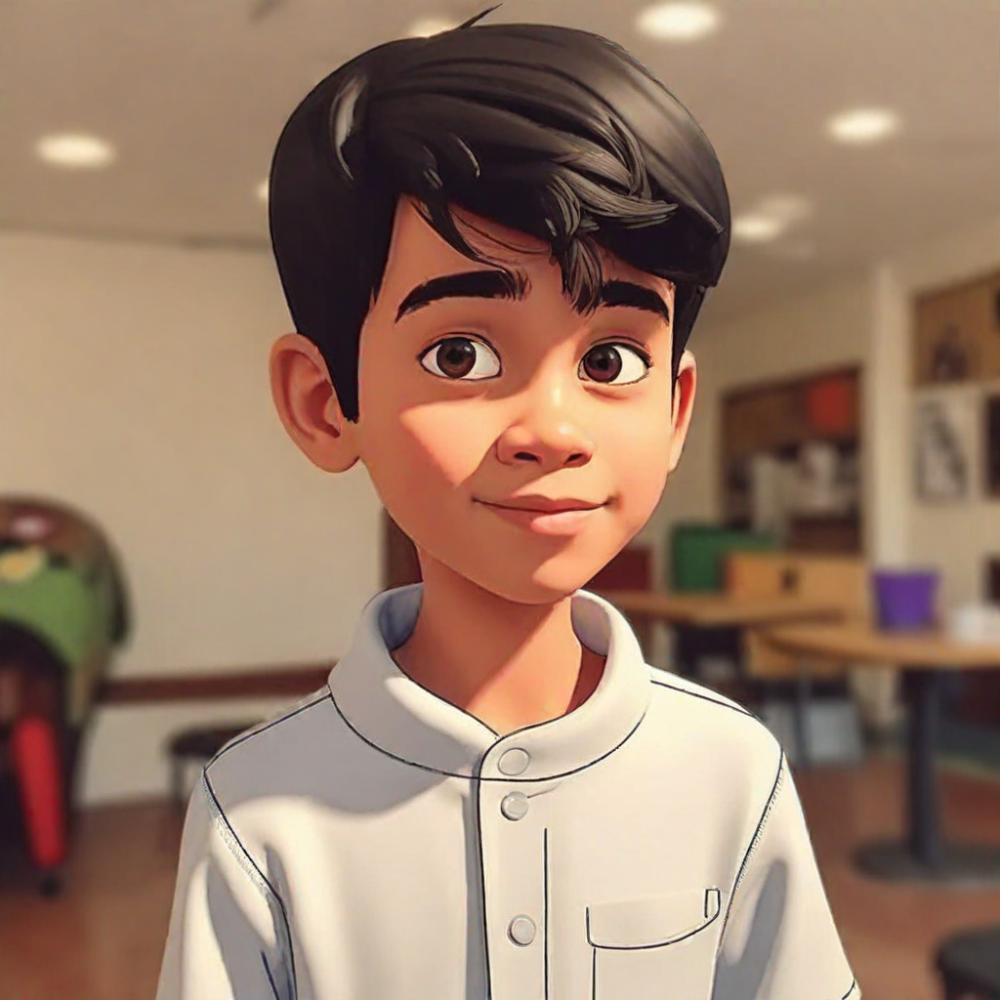

In [51]:
prompt = 'cartoon character'
seed = random.randint(0, 2**15)

images = diversity_distillation(prompt, seed, pipe, base_unet, distilled_unet, distilled_scheduler)

images[0]

  0%|          | 0/15 [00:00<?, ?it/s]

Total Runtime: 7.2034 seconds
Single Runtime: 0.4933 seconds


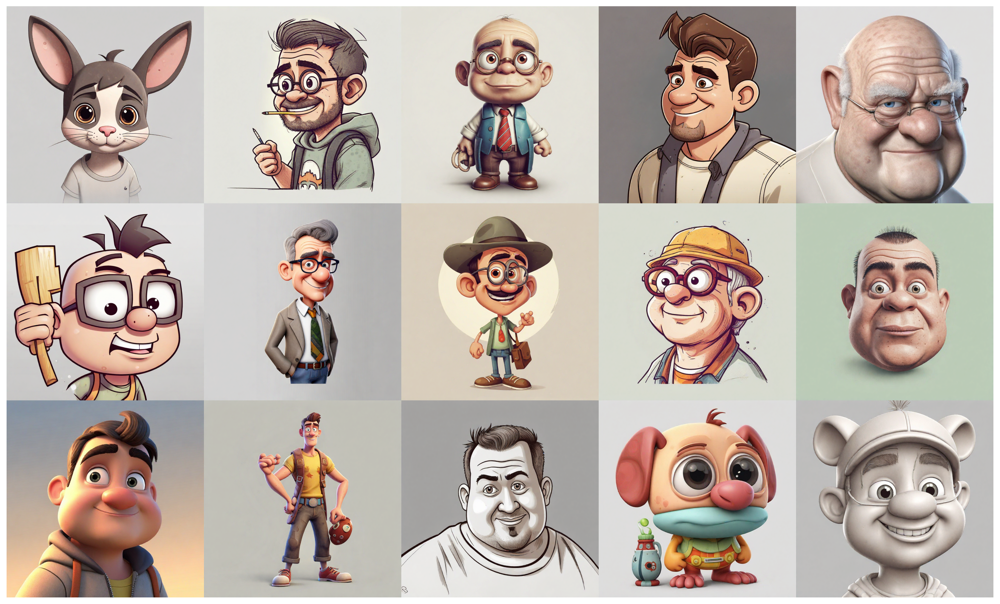

In [53]:
import matplotlib.pyplot as plt
import numpy as np

# User prompt
prompt = "cartoon character"  # Replace with your desired prompt
num_images = 15  # 5x5 grid


nrows = 3
ncols = 5

# Initialize variables
total_time = 0
all_images = []

pipe.set_progress_bar_config(disable=True)
# Generate images
for i in tqdm(range(num_images)):
    # Generate random seed
    seed = np.random.randint(0, 2**32 - 1)
    
    start_time = time.perf_counter()
    
    pil_image = diversity_distillation(prompt, seed, pipe, base_unet, distilled_unet, distilled_scheduler)[0]
    
    end_time = time.perf_counter()
    
    runtime = end_time - start_time
    total_time += runtime
    
    # Convert PIL image to numpy array and append to list
    all_images.append(pil_image)

# Create 5x5 grid with no whitespace
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*3, nrows*3), dpi=200)
plt.subplots_adjust(wspace=0, hspace=0)  # Remove spacing between subplots
fig.patch.set_visible(False)  # Hide the figure's background
for i, ax in enumerate(axes.flat):
    ax.imshow(all_images[i])
    ax.axis('off')  # Remove axes
    ax.set_xticklabels([])  # Remove tick labels
    ax.set_yticklabels([])
    ax.tick_params(left=False, bottom=False)  # Remove ticks

# Remove any remaining borders/margins
plt.tight_layout(pad=0, h_pad=0, w_pad=0)
plt.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0, hspace=0)
plt.margins(0, 0)
plt.gca().xaxis.set_major_locator(plt.NullLocator())
plt.gca().yaxis.set_major_locator(plt.NullLocator())

print(f"Total Runtime: {total_time:.4f} seconds")
print(f"Single Runtime: {runtime:.4f} seconds")
# plt.savefig('grid.png', bbox_inches='tight', pad_inches=0)
plt.show()